In [ ]:
# -*- coding: utf-8 -*-
r"""
Fig.6 Readiness Re-check v1.5 — print-only
- 修复：time 已是“年份”时直接使用（避免错误解析成 1970）
- Shapefile: 使用等间距等值线（LineString），检测2000 m等值线可用性
"""

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from shapely.ops import unary_union
from shapely.prepared import prep
from shapely.geometry import LineString, MultiLineString, Polygon

# ===== 路径 =====
PATH_T2M = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
PATH_ALB = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
PATH_SHP = r"C:\greenland\Greenland_shp\等间距等值线.shp"

# ===== 参数 =====
BASE_START, BASE_END = 2011, 2024
MELT_ELEV_TH = 2000

# ===== 小工具 =====
def pick_var(ds, name_cands):
    for cand in name_cands:
        if cand in ds.data_vars:
            return ds[cand], cand
    kws = [c.lower() for c in name_cands]
    for v in ds.data_vars:
        lv = v.lower()
        if any(k in lv for k in kws):
            return ds[v], v
    first = list(ds.data_vars)[0]
    return ds[first], first

def looks_like_years(arr):
    """若时间坐标本身是年份（整数/浮点且位于 [1800, 2200]），直接当年份用"""
    try:
        vals = np.asarray(arr).astype(float)
    except Exception:
        return False
    if vals.size < 2:
        return False
    ok_range = np.all((vals >= 1800) & (vals <= 2200))
    # 允许小数（比如 1950.0），且基本递增
    diffs = np.diff(vals)
    monotonic = np.all(diffs >= 0) or np.all(diffs <= 0)
    # 不全相等
    diverse = np.nanmax(vals) - np.nanmin(vals) >= 1.0
    return bool(ok_range and monotonic and diverse)

def find_time_coord(obj):
    for c in ["time","valid_valid_valid_valid_valid_time","date","Time","TIME","t","YEAR","year"]:
        if c in obj.coords or c in obj.dims:
            return c
    return None

def to_year_index_safe(da):
    tname = find_time_coord(da)
    info = {"time_coord": tname, "n_time": None, "years": None, "ok": False, "msg": ""}
    if tname is None and "year" in da.dims:
        yrs = pd.Index(da.coords["year"].values).astype(int).tolist()
        info.update({"n_time": len(yrs), "years": yrs, "ok": True, "time_coord": "year"})
        return da, info
    if tname is None:
        info["msg"] = "未找到时间维（time/valid_time/year）"
        return da, info

    coord = da.coords[tname] if tname in da.coords else xr.DataArray(da[tname])

    # 关键修复：如果本身就是“年份”，直接用
    if looks_like_years(coord.values):
        years = np.asarray(coord.values).astype(int)
    else:
        # 正常解析流程
        try:
            if np.issubdtype(coord.dtype, np.datetime64):
                years = pd.DatetimeIndex(coord.values).year
            else:
                years = pd.to_datetime(coord.values).year
        except Exception:
            # 尝试 decode_cf（包成 Dataset）
            try:
                ds_tmp = xr.decode_cf(da.to_dataset(name="__tmp__"))
                tname2 = find_time_coord(ds_tmp["__tmp__"])
                years = pd.DatetimeIndex(ds_tmp["__tmp__"].coords[tname2].values).year
            except Exception as e:
                info["msg"] = f"时间坐标无法解析为年份：{e}"
                return da, info

    da2 = da.assign_coords(year=(tname, years)).swap_dims({tname: "year"}).groupby("year").mean(skipna=True)
    yrs = pd.Index(da2.year.values).astype(int).tolist()
    info.update({"n_time": len(yrs), "years": yrs, "ok": True, "time_coord": tname})
    return da2, info

def get_lat_lon_2d(da):
    lon_name = None; lat_name = None
    for cand in ["lon","longitude","x"]:
        if cand in da.coords: lon_name = cand; break
    for cand in ["lat","latitude","y"]:
        if cand in da.coords: lat_name = cand; break
    if lon_name is None or lat_name is None:
        return None, None, None, "缺少经纬度坐标（lon/lat）"
    lon = da[lon_name]; lat = da[lat_name]
    if lon.ndim == 1 and lat.ndim == 1:
        lon2d, lat2d = np.meshgrid(lon.values, lat.values)
        dims = [d for d in da.dims if d != "year"]
        if len(dims) < 2: return None, None, None, "无法识别二维空间维"
        space_dims = tuple(dims[-2:])
    else:
        lon2d, lat2d = lon.values, lat.values
        dims = [d for d in da.dims if d != "year"]
        if len(dims) < 2: return None, None, None, "无法识别二维空间维"
        space_dims = tuple(dims[-2:])
    return lon2d, lat2d, space_dims, ""

def build_mask_from_polys(lon2d, lat2d, polys):
    from shapely.geometry import Point
    P = prep(unary_union(polys))
    ny, nx = lon2d.shape
    mask = np.zeros((ny, nx), dtype=bool)
    for j in range(ny):
        for i in range(nx):
            if np.isfinite(lon2d[j,i]) and np.isfinite(lat2d[j,i]):
                mask[j,i] = P.contains(Point(float(lon2d[j,i]), float(lat2d[j,i])))
    return mask

def year_coverage(years, y0, y1):
    yrs = pd.Index(years).astype(int).to_list()
    needed = list(range(y0, y1+1))
    missing = [y for y in needed if y not in yrs]
    return {"have": len(needed) - len(missing), "need": len(needed), "missing": missing, "ok": len(missing)==0}

def nan_frac(da): return float(np.isnan(da.values).mean())

# ===== 读取 NetCDF =====
print("\n=== 读取 NetCDF（修复年份解析） ===")
ds_t2m = xr.open_dataset(PATH_T2M)
t2m_var, t2m_name = pick_var(ds_t2m, ["t2m_JJA_Mean","t2m_summer_mean","t2m","T2M"])
t2mY, t2mTI = to_year_index_safe(t2m_var)
print(f"[T2M] 变量: {t2m_name} | 时间轴: {t2mTI['time_coord']} | 年数: {t2mTI['n_time']} | 时间OK: {t2mTI['ok']}")

ds_alb = xr.open_dataset(PATH_ALB)
alb_var, alb_name = pick_var(ds_alb, ["albedo","alb","ALB","albedo_JJA","albedo_summer"])
albY, albTI = to_year_index_safe(alb_var)
print(f"[ALB] 变量: {alb_name} | 时间轴: {albTI['time_coord']} | 年数: {albTI['n_time']} | 时间OK: {albTI['ok']}")

# 年份交集与基准期覆盖
years_common = sorted(list(set(t2mTI.get("years") or []) & set(albTI.get("years") or [])))
if years_common:
    cov = year_coverage(years_common, BASE_START, BASE_END)
    print(f"\n[时间覆盖] 共同年份：{years_common[0]}–{years_common[-1]} | 基准期2011–2024覆盖：{cov['have']}/{cov['need']} | 缺失: {cov['missing']}")
else:
    print("\n[时间覆盖] × 两数据无共同年份")

# 经纬度与网格
print("\n=== 网格与经纬度 ===")
lon2d_a, lat2d_a, space_dims_a, msg_a = get_lat_lon_2d(albY)
lon2d_t, lat2d_t, space_dims_t, msg_t = get_lat_lon_2d(t2mY)
if msg_a: print("  × Albedo 网格问题：", msg_a)
if msg_t: print("  × T2M 网格问题：", msg_t)
if (lon2d_a is not None) and (lon2d_t is not None):
    same_shape = (lon2d_a.shape == lon2d_t.shape)
    print(f"  Albedo 形状: {None if lon2d_a is None else lon2d_a.shape} | T2M 形状: {None if lon2d_t is None else lon2d_t.shape} | 同网格: {same_shape}")
    if not same_shape:
        print("  ！建议：将 T2M 插值到 Albedo 网格（以 Albedo 为基准）")

print("\n=== 全域 NaN 比例 ===")
print(f"  T2M NaN(全域):   {nan_frac(t2mY):.3f}")
print(f"  Albedo NaN(全域): {nan_frac(albY):.3f}")

# ===== 读取 等间距等值线（LineString） =====
print("\n=== 读取等间距等值线（LineString） ===")
gdf = gpd.read_file(PATH_SHP)
print("  CRS:", gdf.crs)
print("  列名:", list(gdf.columns))
geom_types = set(gdf.geometry.geom_type.unique())
print("  几何类型:", geom_types)

# 寻找高程字段
ELEV_FIELD_CANDS = ["elev","ELEV","elevation","Elevation","value","VALUE","Contour","CONTOUR","Z","z","等高","高程","height","HEIGHT"]
elev_field = None
for c in ELEV_FIELD_CANDS:
    if c in gdf.columns:
        elev_field = c; break
print("  高程字段:", elev_field)

if not any(t in {"LineString","MultiLineString"} for t in geom_types):
    print("  × 该shp不是线数据；如果是多边形，请改用 polygon 的文件。")

if elev_field is None:
    print("  × 未找到高程字段（尝试字段名：", ELEV_FIELD_CANDS, "）")
else:
    uniq_levels = pd.to_numeric(gdf[elev_field], errors="coerce").dropna().unique()
    uniq_levels.sort()
    print("  等值线级别（前20个）:", uniq_levels[:20])
    has_2000 = (MELT_ELEV_TH in set(uniq_levels.astype(int)))
    print(f"  是否存在 2000 m 等值线：{has_2000}")
    if not has_2000:
        close_levels = uniq_levels[np.argsort(np.abs(uniq_levels - MELT_ELEV_TH))][:5]
        print("  * 最接近 2000 m 的等级（前5）:", close_levels)

print("\n=== 2000 m 以下区域可构建性评估 ===")
if elev_field is None or not any(t in {"LineString","MultiLineString"} for t in geom_types):
    print("  × 缺少必要信息：无法从线直接构建 <2000m 区域。")
else:
    # 线 → 面 一般需要“外边界”（冰盖轮廓/海岸线）帮助 polygonize
    # 这里只给条件评估，不实际 polygonize
    has_outer_boundary_hint = False  # 你若有冰盖outline polygon，可置 True
    print("  说明：线数据要生成“<2000 m 融化区”面，通常需要冰盖外边界多边形用于封闭；")
    print("        若没有外边界，仅凭等高线 polygonize 往往无法得到正确的区域掩膜。")
    print(f"  外边界是否可用：{has_outer_boundary_hint}（若你提供冰盖 polygon，我们就能自动生成 <2000 m 面掩膜）")

# ===== 最终判定 =====
print("\n=== 最终可行性判断（for Fig.6）===")
ok_time = (albTI["ok"] and t2mTI["ok"] and (len(years_common) > 0))
ok_base = (ok_time and year_coverage(years_common, BASE_START, BASE_END)["ok"]) if years_common else False
ok_grid = (lon2d_a is not None) and (lon2d_t is not None)
ok_lines = (elev_field is not None) and any(t in {"LineString","MultiLineString"} for t in geom_types)

print(f"  时间轴可解析：{ok_time}  | 共同年份范围：{(years_common[0], years_common[-1]) if years_common else None}")
print(f"  基准期2011–2024覆盖完整：{ok_base}")
print(f"  网格可用（有经纬度）：{ok_grid} | 同网格：{(lon2d_a is not None and lon2d_t is not None and lon2d_a.shape==lon2d_t.shape)}")
print(f"  等值线可用（存在高程字段&为线）：{ok_lines}")
print("\n提示：")
if not ok_base:
    print("  → 若共同年份覆盖不到 2011–2024，请确认 albedo/t2m 的年份数组是否都在 2011–2024 内。")
if ok_grid and (lon2d_a is not None and lon2d_t is not None and lon2d_a.shape != lon2d_t.shape):
    print("  → 将 T2M 插值到 Albedo 网格（以 Albedo 为基准）。")
print("  → 若要用等值线生成 <2000 m 融化区，请提供冰盖多边形边界（或我用现成的冰盖外轮廓 shapefile），即可自动 polygonize。")



=== 读取 NetCDF（修复年份解析） ===
[T2M] 变量: t2m | 时间轴: valid_time | 年数: 76 | 时间OK: True
[ALB] 变量: albedo | 时间轴: time | 年数: 75 | 时间OK: True

[时间覆盖] 共同年份：1950–2024 | 基准期2011–2024覆盖：14/14 | 缺失: []

=== 网格与经纬度 ===
  Albedo 形状: (237, 612) | T2M 形状: (239, 616) | 同网格: False
  ！建议：将 T2M 插值到 Albedo 网格（以 Albedo 为基准）

=== 全域 NaN 比例 ===
  T2M NaN(全域):   0.553
  Albedo NaN(全域): 0.549

=== 读取等间距等值线（LineString） ===
  CRS: PROJCS["Polar_Stereographic",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Polar_Stereographic"],PARAMETER["latitude_of_origin",70],PARAMETER["central_meridian",-45],PARAMETER["false_easting",1],PARAMETER["false_northing",1],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",SOUTH],AXIS["Northing",SOUTH]]
  列名: ['OBJECTID', 'Id', 'Contour', 'Shape_Leng', 'geometry']
  几何类型: {'LineString'}
  高程字段: Contour
  等值线级别（前20个）: [1500. 2000. 2500. 3

In [16]:
# -*- coding: utf-8 -*-
r"""
Fig.6 minimal compute v2.1  —— 修复 interp 维度名不一致
关键修复：t2m.interp({<t2m的纬度名>: albedo[<albedo的纬度名>], <t2m的经度名>: albedo[<albedo的经度名>]})
"""

import os
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from shapely.ops import unary_union, polygonize, linemerge
from shapely.prepared import prep
from shapely.geometry import LineString, MultiLineString, Polygon, Point
import warnings
warnings.filterwarnings("ignore")

# ===== 路径 =====
PATH_T2M = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
PATH_ALB = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"
PATH_SHP = r"C:\greenland\Greenland_shp\等间距等值线.shp"
OUT_DIR  = r"C:\greenland\1995bu\fig6_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ===== 参数 =====
BASE_START, BASE_END = 2011, 2024
ROLL_YEARS = 5
MELT_ELEV_TH = 2000
ALBEDO_ICE_FREQ_TH = 0.6  # 冰盖范围判定阈值（≥60% 年非NaN）

# ===== 小工具 =====
def looks_like_years(arr):
    try:
        vals = np.asarray(arr).astype(float)
    except Exception:
        return False
    if vals.size < 2: return False
    ok = np.all((vals >= 1800) & (vals <= 2200))
    mono = np.all(np.diff(vals) >= 0) or np.all(np.diff(vals) <= 0)
    diverse = (np.nanmax(vals) - np.nanmin(vals)) >= 1.0
    return bool(ok and mono and diverse)

def to_yearly(da):
    tname = None
    for c in ["time","valid_time","date","Time","TIME","t","YEAR","year"]:
        if c in da.coords or c in da.dims:
            tname = c; break
    if tname is None and "year" in da.dims:
        return da
    if tname is None:
        raise ValueError("未找到时间维")
    coord = da.coords[tname] if tname in da.coords else xr.DataArray(da[tname])
    if looks_like_years(coord.values):
        years = np.asarray(coord.values).astype(int)
    else:
        try:
            years = pd.to_datetime(coord.values).year
        except Exception:
            ds_tmp = xr.decode_cf(da.to_dataset(name="__tmp__"))
            for c in ["time","valid_time","date","Time","TIME","t","YEAR","year"]:
                if c in ds_tmp["__tmp__"].coords or c in ds_tmp["__tmp__"].dims:
                    coord2 = ds_tmp["__tmp__"].coords[c]; break
            years = pd.to_datetime(coord2.values).year
    return da.assign_coords(year=(tname, years)).swap_dims({tname:"year"}).groupby("year").mean(skipna=True)

def find_lat_lon_names(obj):
    """返回 (lat_name, lon_name) —— 在 coords 里找 lat/latitude & lon/longitude；若没有则报错"""
    lat_name = None
    lon_name = None
    for c in ["lat","latitude"]:
        if c in obj.coords: lat_name = c; break
    for c in ["lon","longitude"]:
        if c in obj.coords: lon_name = c; break
    if lat_name is None or lon_name is None:
        raise ValueError("缺少经纬度坐标（lat/latitude 或 lon/longitude）")
    return lat_name, lon_name

def get_lat_lon_grid(ds):
    lat_name, lon_name = find_lat_lon_names(ds)
    lat = ds[lat_name]; lon = ds[lon_name]
    if lat.ndim == 1 and lon.ndim == 1:
        lat2d, lon2d = np.meshgrid(lat.values, lon.values, indexing="ij")
        # dims：推断最后两维
        dims = [d for d in ds.dims if d != "year"]
        ydim, xdim = dims[-2], dims[-1]
    else:
        lat2d, lon2d = lat.values, lon.values
        dims = [d for d in ds.dims if d != "year"]
        ydim, xdim = dims[-2], dims[-1]
    return lat_name, lon_name, lat2d, lon2d, ydim, xdim

def interp_src_to_dst(src, dst):
    """把 src 插值到 dst 的网格：
       用 src 的坐标名当 key；目标数组取 dst 的 lat/lon 数组"""
    s_lat, s_lon = find_lat_lon_names(src)
    d_lat, d_lon = find_lat_lon_names(dst)
    return src.interp({s_lat: dst[d_lat], s_lon: dst[d_lon]})

def cosine_weight(lat2d):
    return np.cos(np.deg2rad(lat2d))

def area_mean(da, mask=None):
    dims = [d for d in da.dims if d != "year"]
    ydim, xdim = dims[-2], dims[-1]
    lat_name = "lat" if "lat" in da.coords else ("latitude" if "latitude" in da.coords else None)
    if lat_name is None:
        w = xr.ones_like(da.isel(year=0))
    else:
        lat = da[lat_name]
        lat2d = (xr.zeros_like(da.isel(year=0)) + lat) if lat.ndim==1 else lat
        w = xr.zeros_like(da.isel(year=0)) + cosine_weight(lat2d)
    arr = da
    if mask is not None:
        m = xr.DataArray(mask, dims=(ydim, xdim))
        arr = arr.where(m)
        w   = w.where(m)
    num = (arr * w).sum(dim=(ydim, xdim), skipna=True)
    den = (w.where(~np.isnan(arr.isel(year=0)))).sum(dim=(ydim, xdim), skipna=True)
    return num/den

def polygon_mask(lon2d, lat2d, polys):
    P = prep(unary_union(polys))
    ny, nx = lon2d.shape
    mask = np.zeros((ny, nx), dtype=bool)
    for j in range(ny):
        for i in range(nx):
            if np.isfinite(lon2d[j,i]) and np.isfinite(lat2d[j,i]):
                mask[j,i] = P.contains(Point(float(lon2d[j,i]), float(lat2d[j,i])))
    return mask

def anomaly_wrt_period(da, y0, y1):
    base = da.sel(year=slice(y0, y1)).mean("year", skipna=True)
    return da - base

def theil_sen_slope(y, x):
    x = np.asarray(x); y = np.asarray(y)
    m = np.isfinite(x) & np.isfinite(y)
    x = x[m]; y = y[m]
    if len(x) < 3: return np.nan
    slopes = []
    for i in range(len(x)):
        for j in range(i+1, len(x)):
            if x[j] != x[i]:
                slopes.append((y[j]-y[i])/(x[j]-x[i]))
    return np.median(slopes) if slopes else np.nan

# ===== 读取与对齐 =====
ds_t2m = xr.open_dataset(PATH_T2M)
t2m = None
for cand in ["t2m_JJA_Mean","t2m_summer_mean","t2m","T2M"]:
    if cand in ds_t2m.data_vars:
        t2m = ds_t2m[cand]; break
if t2m is None: t2m = list(ds_t2m.data_vars.values())[0]
t2m = to_yearly(t2m)

ds_alb = xr.open_dataset(PATH_ALB)
alb = None
for cand in ["albedo","alb","ALB","albedo_JJA","albedo_summer"]:
    if cand in ds_alb.data_vars:
        alb = ds_alb[cand]; break
if alb is None: alb = list(ds_alb.data_vars.values())[0]
alb = to_yearly(alb)

# 公共年份 & 选择
years = np.intersect1d(t2m.year.values, alb.year.values)
t2m = t2m.sel(year=years); alb = alb.sel(year=years)

# 经纬度与插值
a_lat_name, a_lon_name, a_lat2d, a_lon2d, ydim_a, xdim_a = get_lat_lon_grid(alb)
# 关键修复：用 t2m 自己的坐标名作为 interp key
t2m_i = interp_src_to_dst(t2m, alb)

# ===== 冰盖范围（albedo 非NaN频率）=====
valid_freq = xr.where(~np.isnan(alb), 1, 0).mean("year")
ice_mask = (valid_freq >= ALBEDO_ICE_FREQ_TH).values

# ===== 融化区（<2000 m）—— 2000 m 等高线 polygonize =====
gdf = gpd.read_file(PATH_SHP)
gdf_ll = gdf.to_crs(4326)
if "Contour" not in gdf_ll.columns:
    raise ValueError("等高线 shp 缺少 'Contour' 字段")
g2000 = gdf_ll[pd.to_numeric(gdf_ll["Contour"], errors="coerce")==MELT_ELEV_TH]
if g2000.empty:
    raise ValueError("未找到 2000 m 等值线（Contour==2000）")
merged = linemerge(g2000.geometry.unary_union)
if isinstance(merged, LineString):
    lines = [merged]
elif isinstance(merged, MultiLineString):
    lines = list(merged.geoms)
else:
    lines = list(g2000.geometry)
polys = list(polygonize(lines))
if not polys:
    raise RuntimeError("2000 m 线无法 polygonize 成闭合多边形")
high_poly = polys[int(np.argmax([p.area for p in polys]))]  # ≥2000 m 高区（最大面）

# 冰盖范围：用 ice_mask 的点集凸包近似
ys, xs = np.where(ice_mask)
pts = [Point(float(a_lon2d[y,x]), float(a_lat2d[y,x])) for y,x in zip(ys, xs)]
if len(pts) < 3:
    raise RuntimeError("冰盖掩膜点太少；可降低 ALBEDO_ICE_FREQ_TH（比如 0.4）再试")
ice_hull = unary_union(pts).convex_hull

# 融化区 = 冰盖范围 - 高区
melt_poly = ice_hull.difference(high_poly)

# 栅格化到 Albedo 网格
melt_mask = polygon_mask(a_lon2d, a_lat2d, [melt_poly])
all_mask  = polygon_mask(a_lon2d, a_lat2d, [ice_hull])

# ===== 距平（2011–2024）=====
alb_anom = anomaly_wrt_period(alb, BASE_START, BASE_END)
t2m_anom = anomaly_wrt_period(t2m_i, BASE_START, BASE_END)

# ===== 区域平均时序 =====
def to_series(da, mask):
    return area_mean(da, mask).to_pandas()

df = pd.DataFrame({
    "ALB_anom_all":  to_series(alb_anom, all_mask),
    "ALB_anom_melt": to_series(alb_anom, melt_mask),
    "T2M_anom_melt": to_series(t2m_anom, melt_mask),
})
df.index.name = "year"

# 热年（P90，融化区 T2M_anom）
thr = df["T2M_anom_melt"].quantile(0.90)
df["hot_year"] = (df["T2M_anom_melt"] >= thr).astype(int)
df["hot_count_5yr"] = df["hot_year"].rolling(ROLL_YEARS, min_periods=1).sum()

# ===== 恢复率 R1/R2 =====
def compute_recovery(alb_anom_series, hot_flags):
    years = alb_anom_series.index.values
    hot_years = years[hot_flags.values.astype(bool)]
    rows = []
    for y in hot_years:
        if not all([(y-k) in years for k in (1,2,3)]): 
            continue
        A_pre = alb_anom_series.loc[[y-1,y-2,y-3]].mean()
        A_t   = alb_anom_series.loc[y]
        d_neg = A_t - A_pre
        rec = {"year":int(y), "A":A_t, "A_pre":A_pre, "d_neg":d_neg}
        if (y+1 in years):
            A_p1 = alb_anom_series.loc[y+1]; rec["A_p1"]=A_p1; rec["d_pos1"]=A_p1 - A_pre
            rec["R1"] = (-rec["d_pos1"]/d_neg) if np.isfinite(d_neg) and (d_neg!=0) else np.nan
        else:
            rec["A_p1"]=np.nan; rec["d_pos1"]=np.nan; rec["R1"]=np.nan
        if (y+2 in years):
            A_p2 = alb_anom_series.loc[y+2]; rec["A_p2"]=A_p2; rec["d_pos2"]=A_p2 - A_pre
            rec["R2"] = (-rec["d_pos2"]/d_neg) if np.isfinite(d_neg) and (d_neg!=0) else np.nan
        else:
            rec["A_p2"]=np.nan; rec["d_pos2"]=np.nan; rec["R2"]=np.nan
        rows.append(rec)
    return pd.DataFrame(rows).set_index("year").sort_index() if rows else pd.DataFrame(columns=["A","A_pre","d_neg","A_p1","d_pos1","R1","A_p2","d_pos2","R2"])

events_all  = compute_recovery(df["ALB_anom_all"],  df["hot_year"])
events_melt = compute_recovery(df["ALB_anom_melt"], df["hot_year"])

# ===== 趋势速览（Theil–Sen，每10年）=====
def slope_per_decade(series):
    s = series.dropna()
    if s.empty: return np.nan
    return theil_sen_slope(s.values, s.index.values) * 10.0

summary_trend = pd.DataFrame([
    {"series":"hot_count_5yr (melt)", "slope_per_decade": slope_per_decade(df["hot_count_5yr"])},
    {"series":"R1 (all)",             "slope_per_decade": slope_per_decade(events_all["R1"])},
    {"series":"R1 (melt)",            "slope_per_decade": slope_per_decade(events_melt["R1"])},
])

# ===== 导出 =====
df.to_csv(os.path.join(OUT_DIR, "Fig6_timeseries_all.csv"))
events_all.to_csv(os.path.join(OUT_DIR, "Fig6_events_recovery_all.csv"))
events_melt.to_csv(os.path.join(OUT_DIR, "Fig6_events_recovery_melt.csv"))
summary_trend.to_csv(os.path.join(OUT_DIR, "Fig6_summary_trend.csv"), index=False)

# ===== 快速打印 =====
print("\n阈值 P90 (T2M_anom_melt):", float(thr))
print("热年年份：", df.index[df["hot_year"]==1].tolist())
print("R1 概要（融化区）近10条：\n", events_melt[["R1","R2"]].tail(10))
print("\n趋势斜率(/10yr)：\n", summary_trend)
print("\n输出目录：", OUT_DIR)



阈值 P90 (T2M_anom_melt): 0.2663628886905978
热年年份： [2005, 2010, 2012, 2016, 2019, 2021, 2022, 2023]
R1 概要（融化区）近10条：
              R1        R2
year                     
2005  -2.376518  5.644817
2010  -0.700478 -1.958298
2012   1.260971  0.376128
2016   0.124767  0.532161
2019  -0.142937 -0.255302
2021  41.748566 -9.818558
2022  -0.071172 -0.903850
2023   0.824545       NaN

趋势斜率(/10yr)：
                  series  slope_per_decade
0  hot_count_5yr (melt)          0.000000
1              R1 (all)          0.830918
2             R1 (melt)          1.365747

输出目录： C:\greenland\1995bu\fig6_outputs


C:\Users\11823\AppData\Local\Temp\ipykernel_20524\1795535651.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


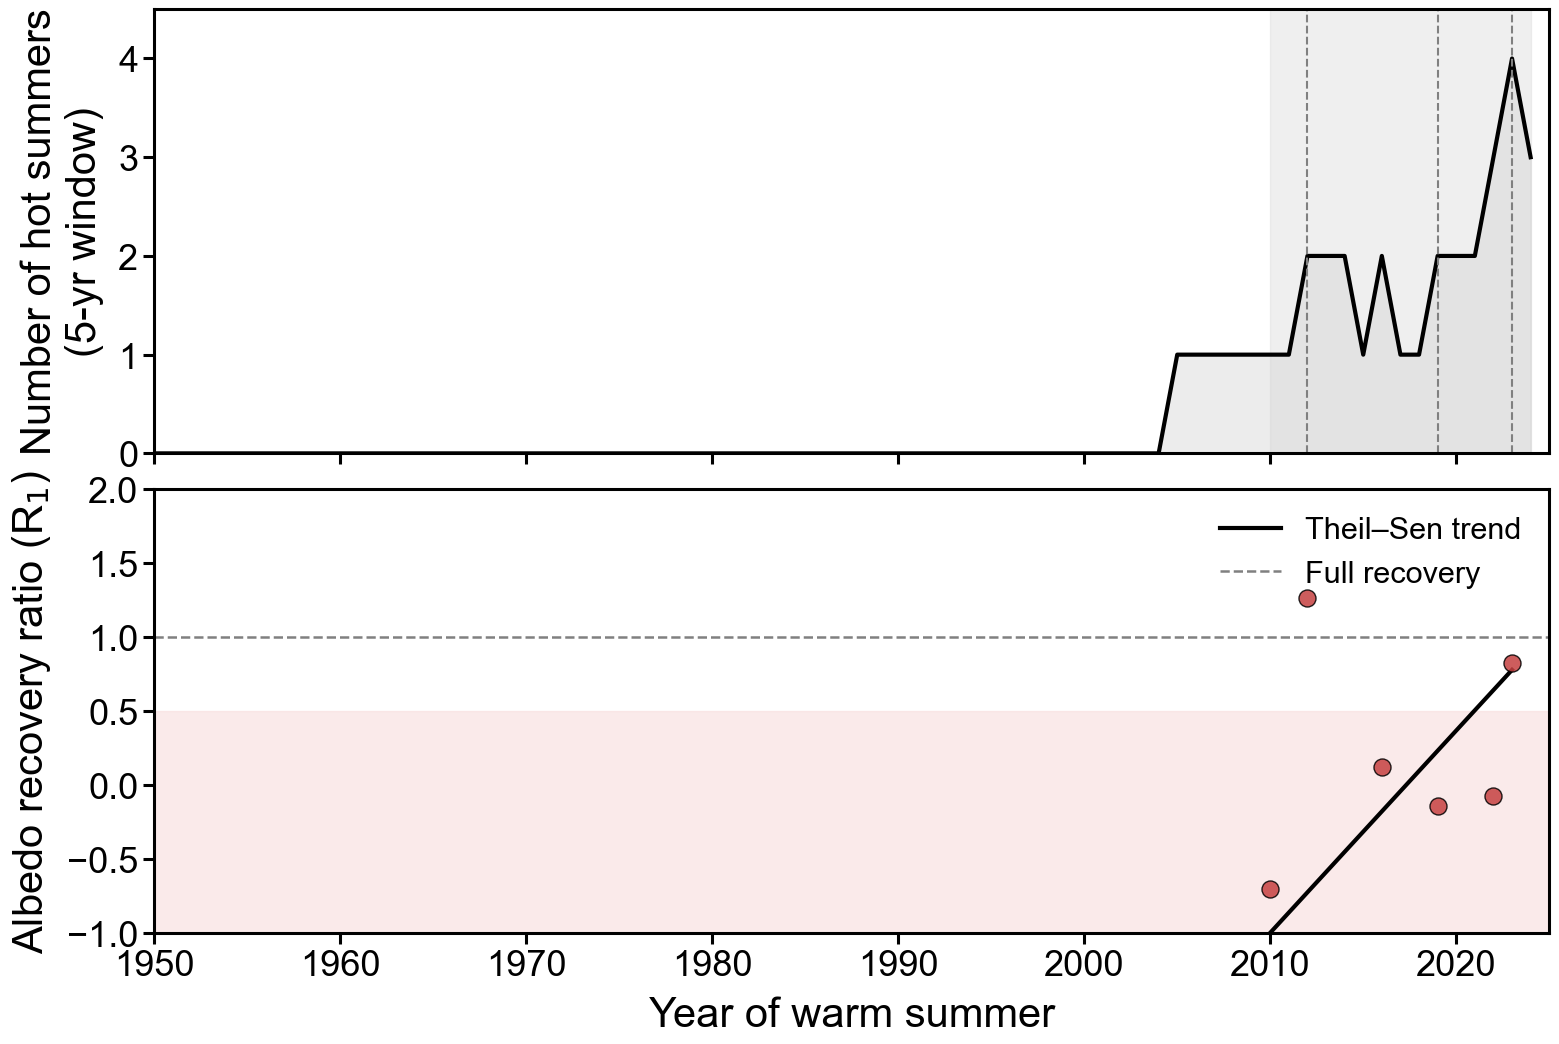


✅ Final Fig.6 saved to: C:\greenland\1995bu\fig6_outputs\Fig6_final_npj_style.png


In [2]:
# -*- coding: utf-8 -*-
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.stats import theilslopes

# ===== 路径 =====
DATA_DIR = r"C:\greenland\1995bu\fig6_outputs"
OUT_FIG  = os.path.join(DATA_DIR, "Fig6_final_npj_style.png")

# ===== 读取数据 =====
df = pd.read_csv(os.path.join(DATA_DIR, "Fig6_timeseries_all.csv"), index_col="year")
events = pd.read_csv(os.path.join(DATA_DIR, "Fig6_events_recovery_melt.csv"), index_col="year")

# ===== 全局参数 =====
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.linewidth"] = 2.2
plt.rcParams["xtick.major.width"] = 2.2
plt.rcParams["ytick.major.width"] = 2.2

FONT = 30
LABEL_PAD = 10

fig, axes = plt.subplots(2, 1, figsize=(18, 12), sharex=True, gridspec_kw={"hspace":0.08})

# ===== (a) 热年次数 =====
ax = axes[0]
y = df["hot_count_5yr"]
ax.fill_between(y.index, y, color="#d0d0d0", alpha=0.4)
ax.plot(y.index, y, color="k", lw=3)

# 灰色背景带表示“现代极端期”
ax.axvspan(2010, 2024, color="lightgray", alpha=0.35)

# 标出关键年份
for yr in [2012, 2019, 2023]:
    ax.axvline(yr, color="gray", lw=1.5, ls="--")

ax.set_ylabel("Number of hot summers\n(5-yr window)", fontsize=FONT, labelpad=LABEL_PAD)
ax.set_xlim(1950, 2025)
ax.set_ylim(0, y.max()+0.5)
ax.tick_params(axis="both", labelsize=FONT-4, width=2.2, length=8)
ax.grid(False)

# ===== (b) 反照率恢复率 =====
ax = axes[1]
r = events["R1"].dropna()
ax.scatter(r.index, r, s=150, color="#c54141", edgecolor="k", zorder=3, alpha=0.85)

# 趋势线 (Theil–Sen)
res = theilslopes(r.values, r.index.values)
yrs = np.array(r.index)
ax.plot(yrs, res[1] + res[0]*yrs, color="k", lw=3, label="Theil–Sen trend")

# 参考线与背景
ax.axhline(1.0, color="gray", lw=1.8, ls="--", label="Full recovery")
ax.axhspan(-1, 0.5, color="#f8dddd", alpha=0.6, zorder=0)

ax.set_ylabel("Albedo recovery ratio (R$_1$)", fontsize=FONT, labelpad=LABEL_PAD)
ax.set_xlabel("Year of warm summer", fontsize=FONT, labelpad=LABEL_PAD)
ax.set_xlim(1950, 2025)
ax.set_ylim(-1, 2)
ax.tick_params(axis="both", labelsize=FONT-4, width=2.2, length=8)
ax.legend(frameon=False, fontsize=FONT-8, loc="upper right")

# ===== 统一样式 =====
for ax in axes:
    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.grid(False)

plt.tight_layout()
plt.savefig(OUT_FIG, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print("\n✅ Final Fig.6 saved to:", OUT_FIG)


In [10]:
# -*- coding: utf-8 -*-
"""
合并 ERA5-Land / ERA5 pressure 三变量的格陵兰夏季均值 (1950–2024)
输出：tccsrrdz.nc （0.1° 空间分辨率，每年一层）
"""

import xarray as xr
import pandas as pd
import numpy as np
import os

# ===========================
# 路径设置
# ===========================
tcc_path  = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenland_tcc_full.nc"
ssrd_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc"
z_path    = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandSP500&200pha.nc"

save_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc"

# ===========================
# 函数定义
# ===========================
def load_ds(path, var):
    """统一命名、时间格式、只提取目标变量"""
    ds = xr.open_dataset(path)[[var]]
    ds = ds.rename({'valid_time': 'time',
                    'latitude': 'lat',
                    'longitude': 'lon'})
    ds['time'] = pd.to_datetime(ds['time'].values)
    return ds

def calc_JJA_mean(ds):
    """筛选6-8月并按年平均"""
    ds_JJA = ds.sel(time=ds['time'].dt.month.isin([6,7,8]))
    ds_JJA = ds_JJA.groupby('time.year').mean('time', skipna=True)
    ds_JJA = ds_JJA.rename({'year': 'time'})
    return ds_JJA

# ===========================
# 读取与处理
# ===========================
print("✅ 读取三个数据集中...")

ds_tcc  = load_ds(tcc_path,  'tcc')
ds_ssrd = load_ds(ssrd_path, 'ssrd')
ds_z    = load_ds(z_path,    'z')

# ERA5 pressure 有气压维度，我们只取 500 hPa
if 'pressure_level' in ds_z.dims:
    ds_z = ds_z.sel(pressure_level=500)

# 计算 JJA 年均值
print("✅ 计算夏季均值 (1950–2024)...")

tcc_JJA  = calc_JJA_mean(ds_tcc)
ssrd_JJA = calc_JJA_mean(ds_ssrd)
z_JJA    = calc_JJA_mean(ds_z)

# ===========================
# 插值对齐到 0.1° 网格 (以 ssrd 为基准)
# ===========================
print("✅ 空间插值到 0.1° 网格 (ERA5-Land 分辨率)...")

target_lat = ds_ssrd.lat
target_lon = ds_ssrd.lon

tcc_interp = tcc_JJA.interp(lat=target_lat, lon=target_lon)
z_interp   = z_JJA.interp(lat=target_lat, lon=target_lon)

# ===========================
# 合并成单个 Dataset
# ===========================
print("✅ 合并变量...")

merged = xr.Dataset({
    'tcc':  tcc_interp.tcc,
    'ssrd': ssrd_JJA.ssrd,
    'z':    z_interp.z
})

# 时间范围裁剪一致 (1950–2024)
years = np.arange(1950, 2025)
merged = merged.sel(time=merged.time.isin(years))

# 添加属性
merged.attrs['description'] = 'ERA5-Land & ERA5 pressure Greenland summer (JJA) mean, 1950–2024'
merged.attrs['creator'] = '汝清 @ TU Berlin'
merged.attrs['variables'] = 'tcc (0–1), ssrd (J/m²), z (m²/s², 500hPa)'
merged.attrs['resolution'] = '0.1° × 0.1°'
merged.attrs['period'] = 'JJA (June–August)'
merged.attrs['created'] = pd.Timestamp.now().strftime('%Y-%m-%d')

# ===========================
# 保存文件
# ===========================
print(f"💾 保存至: {save_path}")
merged.to_netcdf(save_path, format='NETCDF4', engine='netcdf4')
print("✅ 完成！tccsrrdz.nc 已生成。")


✅ 读取三个数据集中...
✅ 计算夏季均值 (1950–2024)...
✅ 空间插值到 0.1° 网格 (ERA5-Land 分辨率)...
✅ 合并变量...
💾 保存至: C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc
✅ 完成！tccsrrdz.nc 已生成。


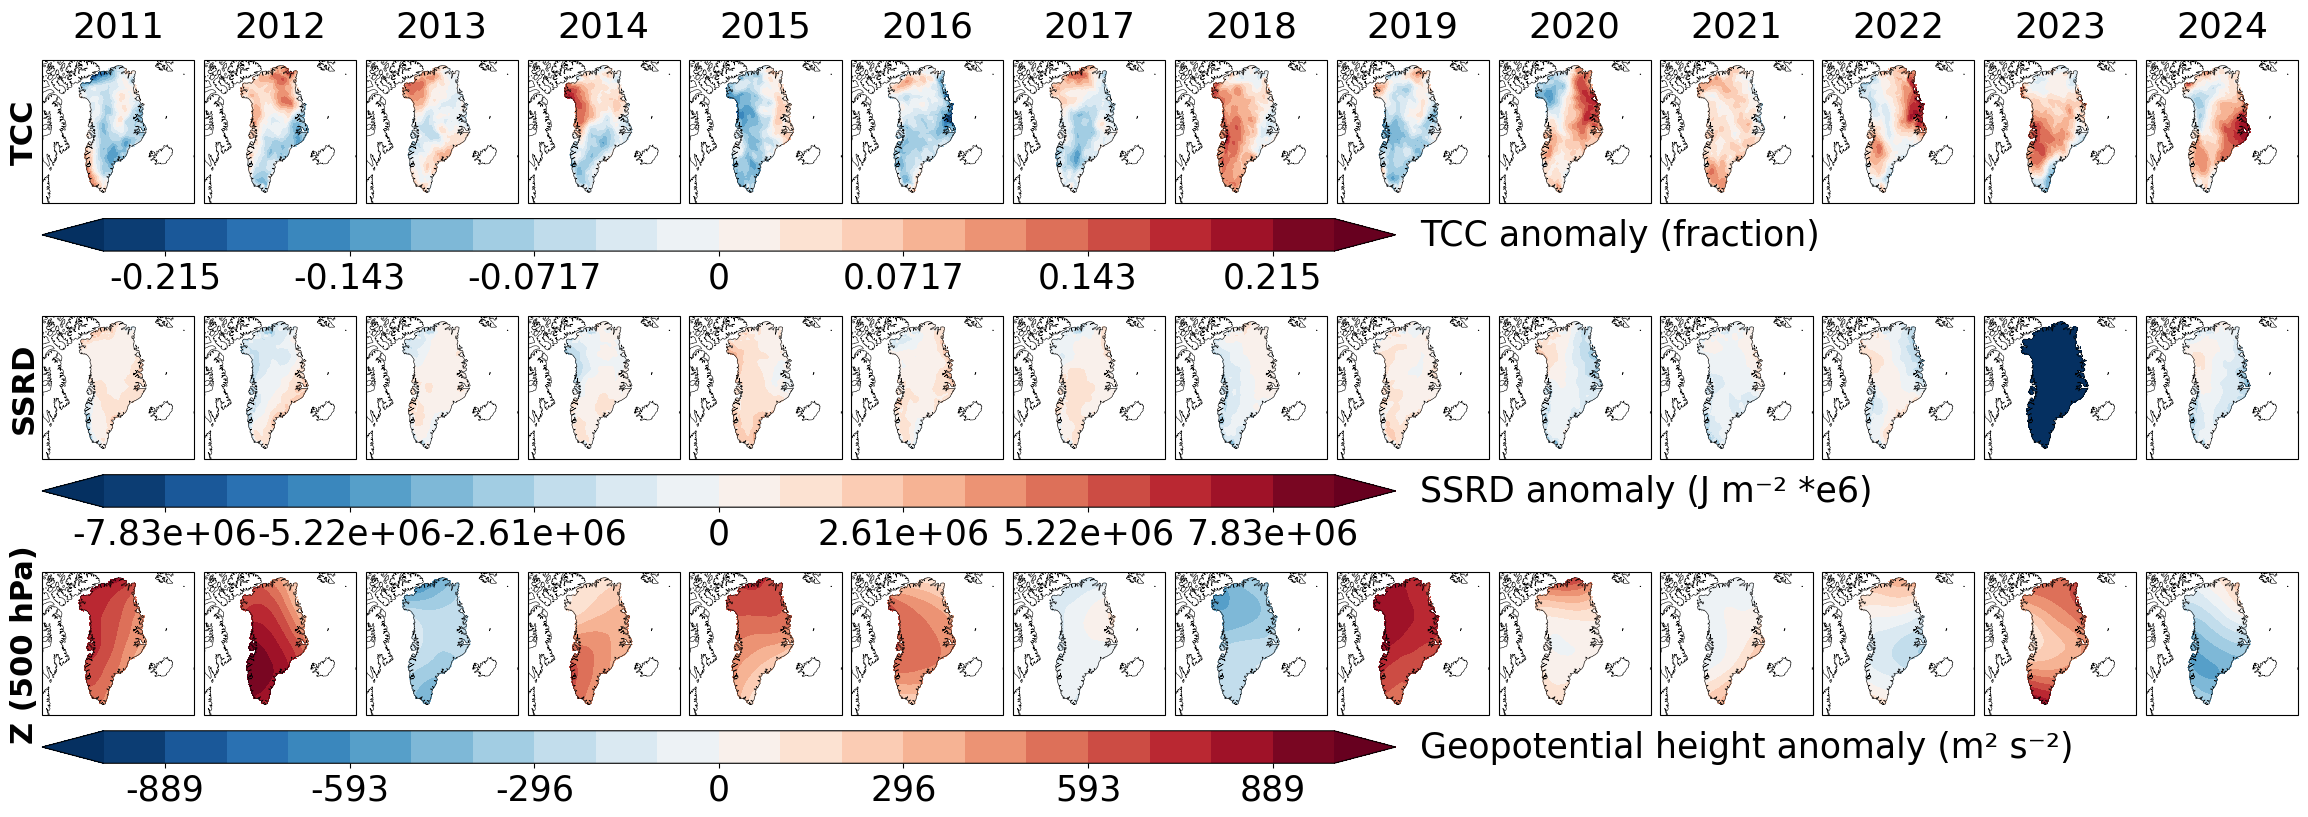

In [15]:
# -*- coding: utf-8 -*-
"""
Greenland JJA anomalies (TCC, SSRD, Z)
→ Each variable row has its own shortened colorbar aligned with the row width
→ Unit labels aligned visually to end of colorbar
"""

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ==================== 全局参数 ====================
FONT_SIZE = 30
ROW_LABEL_SIZE = 22
YEAR_FONT_SIZE = 26
CBAR_LABEL_SIZE = 25
CBAR_TICK_SIZE = 25

FIG_W, FIG_H = 24, 13
EXTENT = [-65, -12, 58, 84]
CENTRAL_LON = -40

ROW_H = 0.12
ROW_GAP = 0.045
CBAR_H = 0.025
CBAR_PAD = 0.012

# =================================================
# 1. 读取数据
# =================================================
file_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc"
ds = xr.open_dataset(file_path)

years = list(range(2011, 2025))

def anomalies_vs_clim(da, years):
    clim = da.mean("time")
    anos = {y: da.sel(time=y) - clim for y in years}
    vmax = np.nanmax(np.abs([float(anos[y].max()) for y in anos]))
    return anos, vmax

ano_tcc, vmax_tcc   = anomalies_vs_clim(ds["tcc"],  years)
ano_ssrd, vmax_ssrd = anomalies_vs_clim(ds["ssrd"], years)
ano_z,   vmax_z     = anomalies_vs_clim(ds["z"],    years)

# =================================================
# 2. 绘图
# =================================================
proj = ccrs.NorthPolarStereo(central_longitude=CENTRAL_LON)
fig = plt.figure(figsize=(FIG_W, FIG_H))

left, right = 0.03, 0.97
top = 0.94
gap_w = 0.004
N = len(years)
ax_w = (right - left - gap_w * (N - 1)) / N

def plot_row(y_top, anodict, vmax, label_text, cbar_label):
    """绘制一整行 + 短色条对齐"""
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    axes = []
    for i, y in enumerate(years):
        x0 = left + i * (ax_w + gap_w)
        ax = fig.add_axes([x0, y_top - ROW_H, ax_w, ROW_H], projection=proj)
        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.3)
        ax.set_xticks([]); ax.set_yticks([])
        cf = ax.contourf(
            anodict[y]["lon"], anodict[y]["lat"], anodict[y],
            levels=np.linspace(-vmax, vmax, 21),
            cmap="RdBu_r", norm=norm, extend="both",
            transform=ccrs.PlateCarree()
        )
        axes.append(ax)

    # 左侧标签
    axes[0].text(-0.02, 0.5, label_text, transform=axes[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE,
                 weight='bold', rotation=90)

    # ========== 色条 ==========
    first_ax = axes[0].get_position()
    last_ax  = axes[-1].get_position()
    total_w  = last_ax.x1 - first_ax.x0

    # 短色条长度设置（例如占行宽 0.6）
    cbar_ratio = 0.60
    cbar_width = total_w * cbar_ratio
    cbar_x0 = first_ax.x0 
    cbar_y0 = first_ax.y0 - CBAR_PAD - CBAR_H

    # 画色条
    cax = fig.add_axes([cbar_x0, cbar_y0, cbar_width, CBAR_H])
    cb = fig.colorbar(cf, cax=cax, orientation="horizontal", format="%.3g")
    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE)

    # 单位文字紧随其后（右对齐至行末）
    fig.text(cbar_x0 + cbar_width + 0.01, cbar_y0 + CBAR_H/2,
             cbar_label, fontsize=CBAR_LABEL_SIZE,
             va='center', ha='left')

    # 返回下一个行起点
    return cbar_y0 - ROW_GAP

# =================================================
# 3. 绘制三行
# =================================================
y_current = top
y_current = plot_row(y_current, ano_tcc,  vmax_tcc,  "TCC",  "TCC anomaly (fraction)")
y_current = plot_row(y_current, ano_ssrd, vmax_ssrd, "SSRD", "SSRD anomaly (J m⁻² *e6)")
_          = plot_row(y_current, ano_z,    vmax_z,    "Z (500 hPa)", "Geopotential height anomaly (m² s⁻²)")

# =================================================
# 4. 年份标签
# =================================================
for i, y in enumerate(years):
    x0 = left + i * (ax_w + gap_w)
    fig.text(x0 + ax_w/2, top + 0.008, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

plt.show()


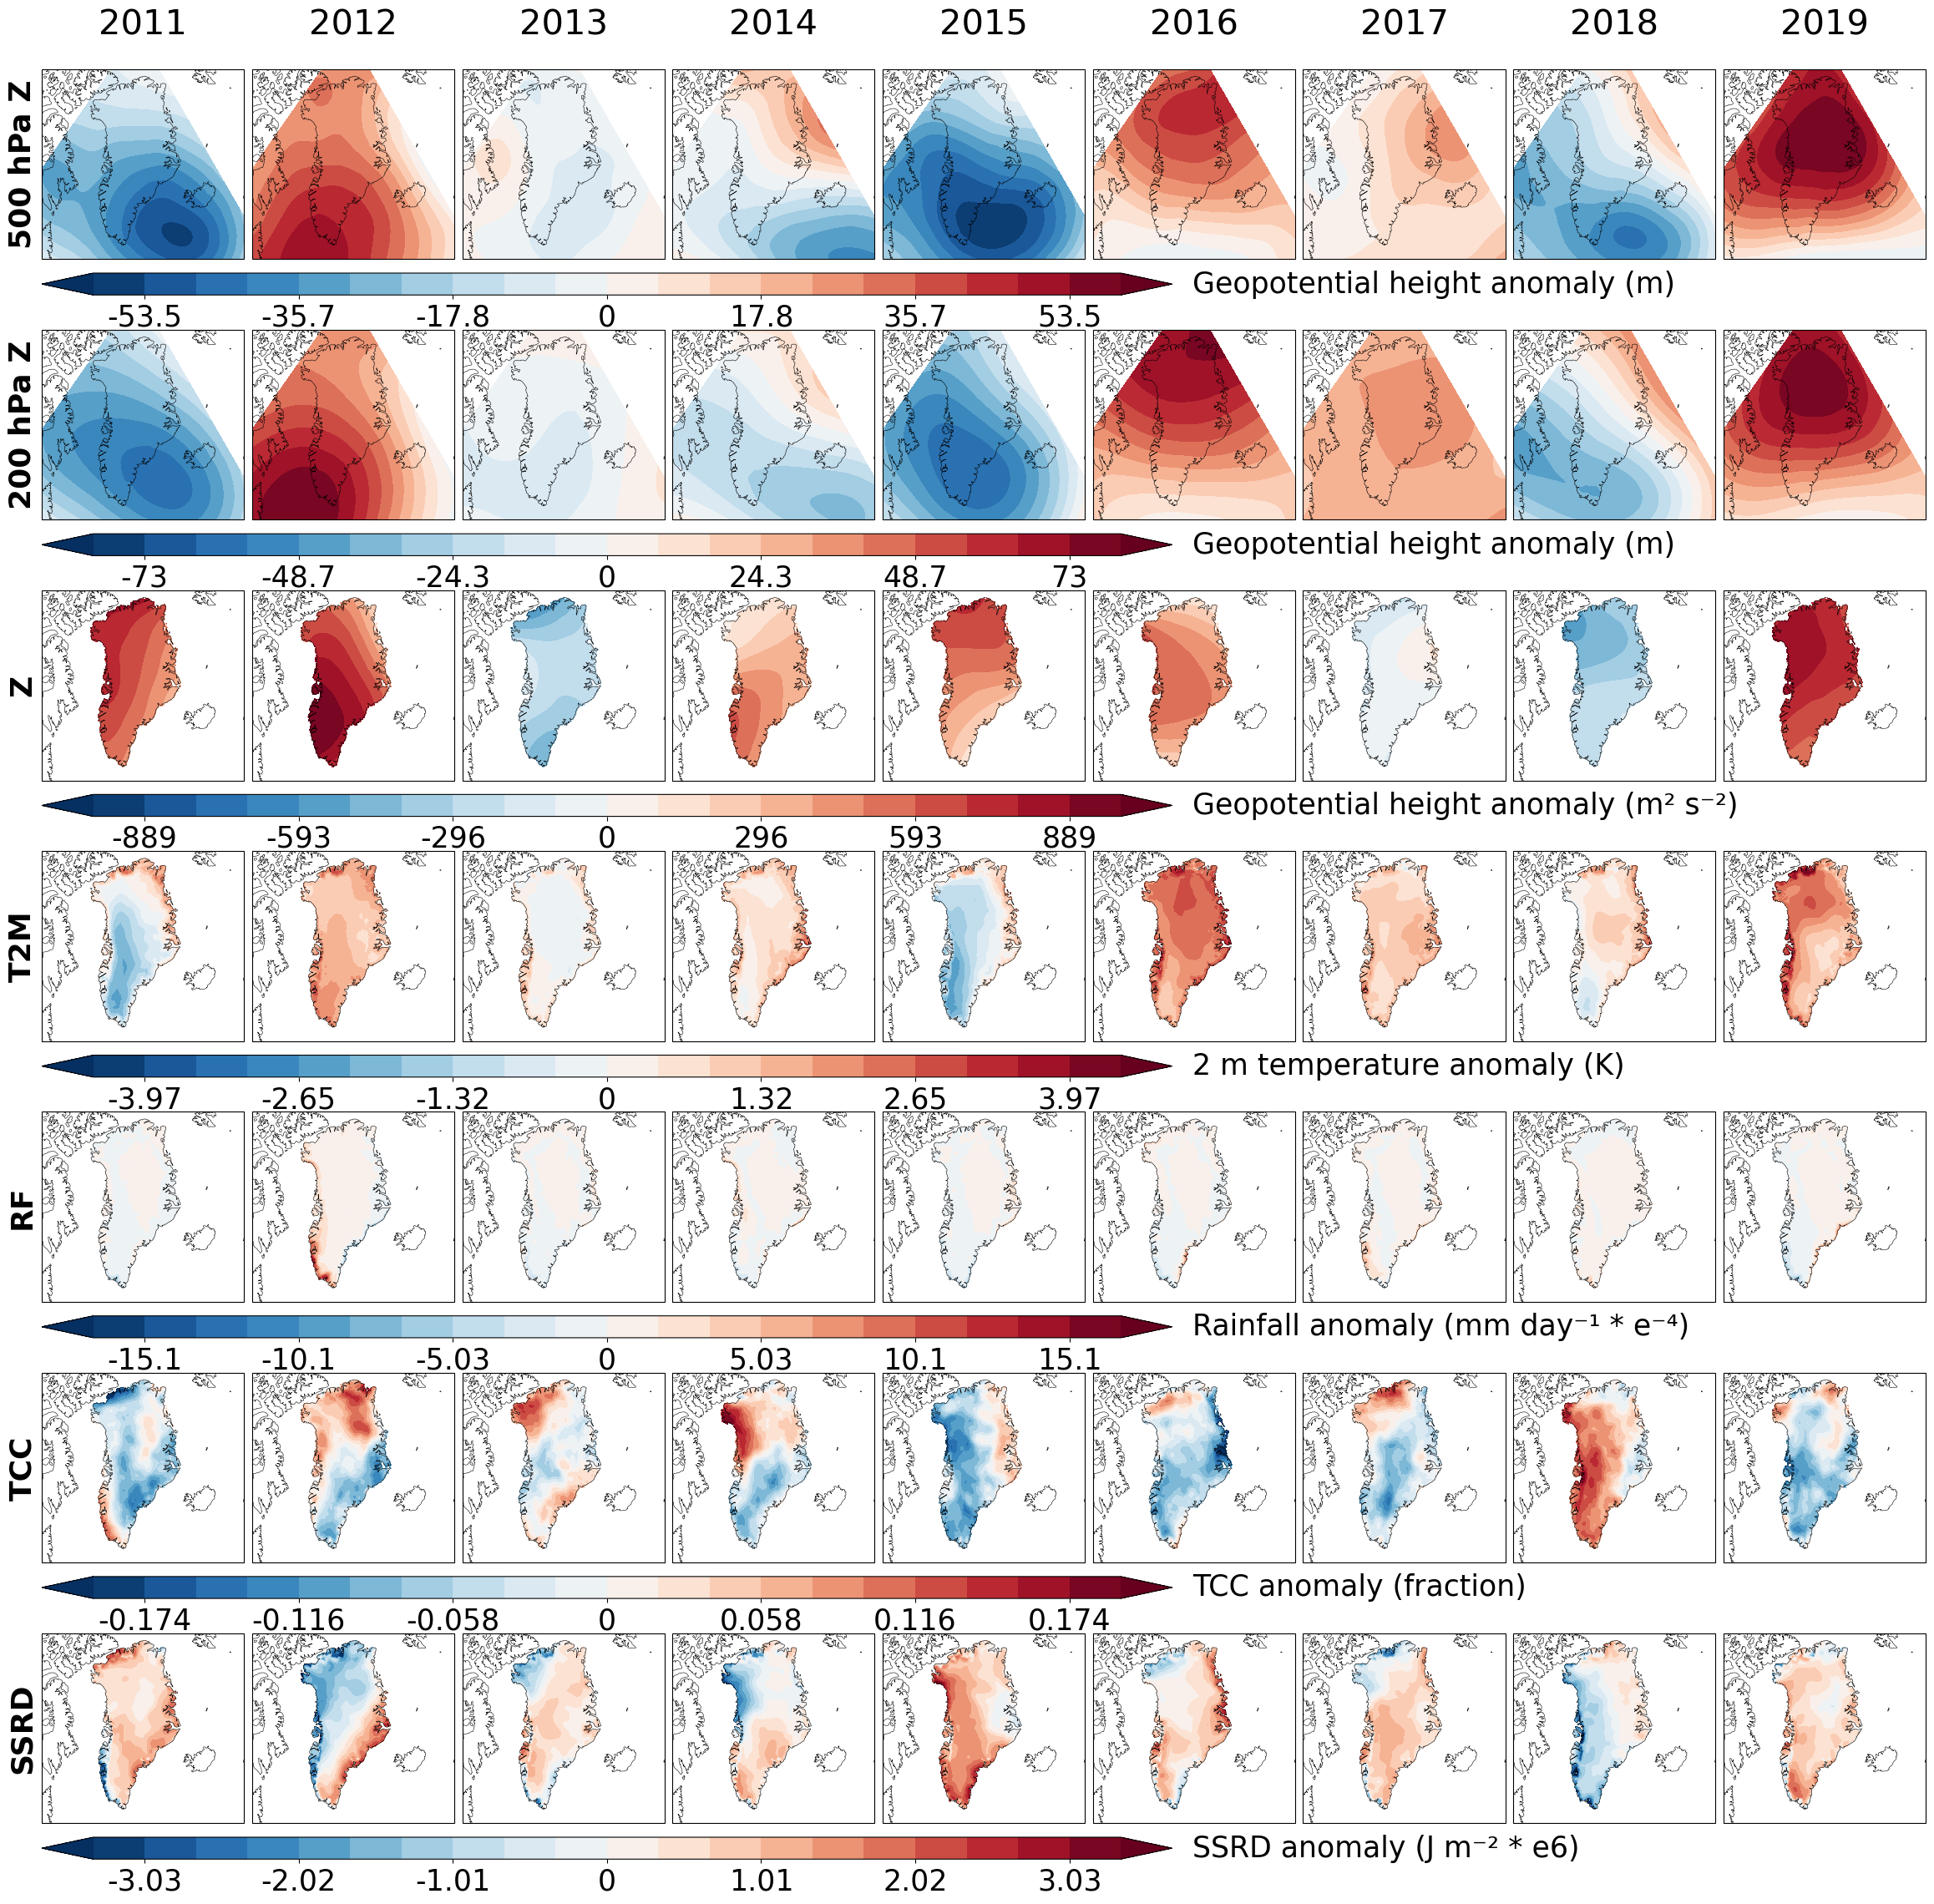

In [24]:
# -*- coding: utf-8 -*-
"""
Greenland JJA anomalies (2011–2019)
顺序: 500 hPa → 200 hPa → Z → T2M → RF → TCC → SSRD
SSRD 色条数值除以 1e6 后保留 3 位有效数字（匹配单位 e6）
"""

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ==================== 全局参数 ====================
FONT_SIZE       = 30
ROW_LABEL_SIZE  = 26
YEAR_FONT_SIZE  = 30
CBAR_LABEL_SIZE = 25
CBAR_TICK_SIZE  = 25

FIG_W, FIG_H = 24, 21
EXTENT = [-65, -12, 58, 84]
CENTRAL_LON = -40

ROW_H    = 0.12
ROW_GAP  = 0.014       # ← 新行距
CBAR_H   = 0.0125
CBAR_PAD = 0.008

# ==================== 文件路径 ====================
file_tccsrrdz = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc"
file_z        = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5pressure500&200pha.nc"
file_rf       = r"C:\greenland\sf_tp_rf.nc"
file_t2m      = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"

# ==================== 年份设置 ====================
years = list(range(2011, 2020))

# ==================== 公用函数 ====================
def anomalies_vs_clim(da, years):
    clim = da.mean("time")
    anos = {}
    for y in years:
        try:
            sub = da.sel(time=da["time"].dt.year == y).mean("time")
        except Exception:
            sub = da.sel(time=da["time"].astype(str).str.startswith(str(y))).mean("time")
        anos[y] = sub - clim
    vmax = np.nanmax(np.abs([float(anos[y].max()) for y in anos]))
    return anos, vmax

# ---------- 读取 tcc, ssrd, z ----------
ds = xr.open_dataset(file_tccsrrdz)
ano_tcc, vmax_tcc   = anomalies_vs_clim(ds["tcc"],  years)

# ✅ SSRD 除以 1e6，使图例与单位匹配
ssrd_scaled = ds["ssrd"] / 1e6
ano_ssrd, vmax_ssrd = anomalies_vs_clim(ssrd_scaled, years)

ano_z, vmax_z       = anomalies_vs_clim(ds["z"], years)

# ---------- 读取 z500, z200 ----------
ds_z = xr.open_dataset(file_z)
z500 = (ds_z["z"].sel(pressure_level=500) / 9.80665).rename({"valid_time": "time"})
z200 = (ds_z["z"].sel(pressure_level=200) / 9.80665).rename({"valid_time": "time"})
ano500, vmax500 = anomalies_vs_clim(z500, years)
ano200, vmax200 = anomalies_vs_clim(z200, years)
vmax_z_all = max(vmax_z, vmax500, vmax200)

# ---------- 读取 RF, T2M ----------
def open_da_variants(path, var_candidates, scale=1.0):
    ds = xr.open_dataset(path)
    for v in var_candidates:
        if v in ds:
            da = ds[v]
            break
    else:
        key = [k for k in ds.data_vars if any(v.lower() in k.lower() for v in var_candidates)]
        if not key:
            raise KeyError(f"No variable found in {var_candidates}")
        da = ds[key[0]]
    rename = {}
    for d in da.dims:
        dl = d.lower()
        if dl in ["valid_time","time"]: rename[d] = "time"
        if dl in ["lat","latitude"]:    rename[d] = "latitude"
        if dl in ["lon","longitude"]:   rename[d] = "longitude"
    return da.rename(rename) * scale

rf  = open_da_variants(file_rf,  ["rf","rain","rainfall","tp"]) * 1e4
t2m = open_da_variants(file_t2m, ["t2m","2t","t2m_jja_mean"])
anorf,  vmaxrf  = anomalies_vs_clim(rf,  years)
anot2m, vmaxt2m = anomalies_vs_clim(t2m, years)

# ==================== 绘图布局 ====================
proj = ccrs.NorthPolarStereo(central_longitude=CENTRAL_LON)
fig = plt.figure(figsize=(FIG_W, FIG_H))

left, right = 0.03, 0.97
top = 0.96
gap_w = 0.004
N = len(years)
ax_w = (right - left - gap_w * (N - 1)) / N

def plot_row(y_top, anodict, vmax, label_text, cbar_label, fmt="%.3g"):
    """绘制一整行 + 左对齐短色条"""
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    axes = []
    for i, y in enumerate(years):
        x0 = left + i * (ax_w + gap_w)
        ax = fig.add_axes([x0, y_top - ROW_H, ax_w, ROW_H], projection=proj)
        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.3)
        ax.set_xticks([]); ax.set_yticks([])
        cf = ax.contourf(
            anodict[y]["lon"] if "lon" in anodict[y].coords else anodict[y]["longitude"],
            anodict[y]["lat"] if "lat" in anodict[y].coords else anodict[y]["latitude"],
            anodict[y],
            levels=np.linspace(-vmax, vmax, 21),
            cmap="RdBu_r", norm=norm, extend="both",
            transform=ccrs.PlateCarree()
        )
        axes.append(ax)

    # 左侧标签
    axes[0].text(-0.025, 0.5, label_text, transform=axes[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE,
                 weight='bold', rotation=90)

    # 左对齐色条
    first_ax = axes[0].get_position()
    cbar_x0 = first_ax.x0
    cbar_y0 = first_ax.y0 - CBAR_PAD - CBAR_H
    cbar_width = (right - left) * 0.6
    cax = fig.add_axes([cbar_x0, cbar_y0, cbar_width, CBAR_H])

    cb = fig.colorbar(cf, cax=cax, orientation="horizontal", format=fmt)
    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE)

    fig.text(cbar_x0 + cbar_width + 0.01, cbar_y0 + CBAR_H/2,
             cbar_label, fontsize=CBAR_LABEL_SIZE,
             va='center', ha='left')

    return cbar_y0 - ROW_GAP

# ==================== 绘制行 ====================
y_current = top
y_current = plot_row(y_current, ano500,   vmax500,   "500 hPa Z", "Geopotential height anomaly (m)")
y_current = plot_row(y_current, ano200,   vmax200,   "200 hPa Z", "Geopotential height anomaly (m)")
y_current = plot_row(y_current, ano_z,    vmax_z,    "Z",         "Geopotential height anomaly (m² s⁻²)")
y_current = plot_row(y_current, anot2m,   vmaxt2m,   "T2M",       "2 m temperature anomaly (K)")
y_current = plot_row(y_current, anorf,    vmaxrf,    "RF",        "Rainfall anomaly (mm day⁻¹ * e⁻⁴)")
y_current = plot_row(y_current, ano_tcc,  vmax_tcc,  "TCC",       "TCC anomaly (fraction)")
# ✅ SSRD 特殊处理：数据已除以1e6，刻度三位有效数字
y_current = plot_row(y_current, ano_ssrd, vmax_ssrd, "SSRD",      "SSRD anomaly (J m⁻² * e6)", fmt="%.3g")

# ==================== 年份标签 ====================
for i, y in enumerate(years):
    x0 = left + i * (ax_w + gap_w)
    fig.text(x0 + ax_w/2, top + 0.010, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

plt.show()
